<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#000000; padding:34px 38px 30px 38px; border-radius:14px;">
<p style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#A6A6A6; margin:0; font-size:0.85em; font-weight:600; letter-spacing:0.16em;">CHARMM FORCE FIELD · ALKYLSILANE MONOLAYERS ON SILICA</p>
<h1 style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#ffffff; margin:12px 0 14px 0; font-size:2.2em; font-weight:700; line-height:1.15; letter-spacing:-0.01em;">The force-field terms at the Si–C bond<br>against quantum chemistry</h1>
<p style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#E0E0E0; margin:0; font-size:1.12em; font-weight:400; line-height:1.55;">CHARMM has no parameters for the bond between the silicon of the head group and the first carbon of the alkyl chain, nor for the angles and dihedrals at this bond. Here the terms of the force field at the Si–C bond are compared with relaxed scans of a model molecule at the HF/6-31G* level: the bond, the angle and the dihedral at the Si–C bond, each next to the same coordinate in the alkyl chain, whose CHARMM terms are the reference.</p>
<p style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#BDBDBD; margin:18px 0 0 0; font-size:0.95em; font-weight:500;">Model molecule: octylsilanetriol, Si(OH)<sub>3</sub>–C<sub>8</sub>H<sub>17</sub> (<i>L</i> = 8), neutral, in the gas phase · quantum chemistry: ORCA, HF/6-31G* · force field: GROMACS</p>
</div>
<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#C62828; margin-top:12px; padding:14px 22px; border-radius:10px;"><p style="font-family:'Avenir Next', 'Segoe UI', 'Helvetica Neue', Helvetica, Arial, sans-serif; color:#ffffff; margin:0; font-size:1.05em; font-weight:600; line-height:1.5;">This is personal work, and the results are not in any paper, published or unpublished.</p></div>
<div style="box-sizing:border-box; width:calc(100% - 40px);">

The notebook answers four questions:

1. Does the force field give the equilibrium geometry of the relaxed molecule at the Si–C bond?
2. How close is the force field to the ORCA scans of the bond and the angle at the Si–C bond?
3. Is the dihedral at the Si–C bond, the softest term and the one that sets the trans and gauche conformations, as close to ORCA as the CHARMM dihedral of the alkyl chain?
4. How close are the terms with the oxygens of the head group?

Every scan is compared with the force-field energy of the whole molecule (MM), computed with GROMACS for the same structures. Folders: `ORCA_results` (relaxation and scans), `force_field_energies` (GROMACS), `figures` (every plot as a PDF file), `doc` (the schematic drawings as PDF and PNG files, made with `make_drawings.py`), `ForceField` (the force-field files) and `GROMACS_force_field` (the same force field in one GROMACS force-field folder).

<p>Sections: <span style="background-color:#2A9D8F; color:#ffffff; padding:2px 9px; border-radius:10px;">relaxation</span> <span style="background-color:#3D5A80; color:#ffffff; padding:2px 9px; border-radius:10px;">bonds</span> <span style="background-color:#9C4F6E; color:#ffffff; padding:2px 9px; border-radius:10px;">angles</span> <span style="background-color:#4F772D; color:#ffffff; padding:2px 9px; border-radius:10px;">dihedrals</span> <span style="background-color:#6B5B95; color:#ffffff; padding:2px 9px; border-radius:10px;">terms with oxygen</span> <span style="background-color:#37474F; color:#ffffff; padding:2px 9px; border-radius:10px;">summary</span> <span style="background-color:#005F73; color:#ffffff; padding:2px 9px; border-radius:10px;">force field</span> <span style="background-color:#6C757D; color:#ffffff; padding:2px 9px; border-radius:10px;">references</span></p>

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code installs the Python packages that the notebook needs (numpy, pandas, matplotlib, ase, nglview and ipywidgets).</div>

In [ ]:
%pip install -q numpy pandas matplotlib ase nglview==3.0.8 ipywidgets

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code imports the packages and sets the folders, the colors and the look of the plots. It defines the helpers used below: the two-panel figure, the legend row, the rms difference, the drawings and the structure viewers.</div>

In [2]:
from pathlib import Path

import ipywidgets as widgets
import matplotlib.pyplot as plt
import nglview
import numpy as np
import pandas as pd
from ase import Atoms
from IPython.display import Image, display
from matplotlib.lines import Line2D

RELAXED = Path('ORCA_results/relaxation')
SCANS = Path('ORCA_results/scans')
ENERGIES = Path('force_field_energies')
DOC = Path('doc')                  # the schematic drawings: fixed files, made with make_drawings.py
FIGURES = Path('figures')          # the plots of the notebook
HARTREE = 2625.4996        # kJ/mol
BOHR = 0.052917721         # nm
OXYGEN = 5                 # the oxygen of the scans with an oxygen: atom 5 of the ORCA files, counted from 0
# colors of the ORCA points: the coordinate at the Si-C bond, the same coordinate in the chain, with an oxygen
SI_C_COLOR = '#B7371B'
CHAIN_COLOR = '#0D4F8B'
OXYGEN_COLOR = '#756BB1'
LINE_COLOR = '#282B28'
# the look of all plots: Arial, and the text sizes and lines of the drawings
plt.rcParams.update({'font.family': 'sans-serif', 'font.sans-serif': ['Arial'], 'pdf.fonttype': 42,
                     'mathtext.default': 'it', 'axes.unicode_minus': False, 'font.size': 8.5,
                     'axes.labelsize': 8.5, 'xtick.labelsize': 8.0, 'ytick.labelsize': 8.0, 'legend.fontsize': 7.5,
                     'axes.linewidth': 1.2, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.labelpad': 2.5, 'xtick.direction': 'in', 'ytick.direction': 'in',
                     'xtick.major.size': 4.2, 'ytick.major.size': 4.2, 'xtick.major.width': 1.0,
                     'ytick.major.width': 1.0, 'xtick.minor.size': 2.0, 'ytick.minor.size': 2.0,
                     'xtick.minor.width': 0.7, 'ytick.minor.width': 0.7, 'xtick.minor.visible': True,
                     'ytick.minor.visible': True, 'xtick.major.pad': 3.0, 'ytick.major.pad': 3.0,
                     'lines.linewidth': 1.45, 'lines.markersize': 4.25, 'lines.dashed_pattern': [4.0, 2.2],
                     'lines.scale_dashes': False, 'legend.frameon': False, 'legend.handlelength': 1.8,
                     'legend.handletextpad': 0.4, 'legend.columnspacing': 1.6, 'savefig.dpi': 300})
FIGURES.mkdir(exist_ok=True)


def two_panels():
    """Figure of 7.0 x 2.6 inches with two panels side by side, (a) and (b)."""
    fig = plt.figure(figsize=(7.0, 2.6))
    left = fig.add_axes([0.085, 0.165, 0.385, 0.62])
    right = fig.add_axes([0.595, 0.165, 0.385, 0.62])
    left.text(-0.2, 1.03, '(a)', transform=left.transAxes, fontsize=9.5, va='bottom')
    right.text(-0.2, 1.03, '(b)', transform=right.transAxes, fontsize=9.5, va='bottom')
    return fig, left, right


def top_legend(fig, entries):
    """The legend entries in one row at the top of a figure."""
    fig.legend(handles=entries, loc='upper center', bbox_to_anchor=(0.5, 1.0), ncol=len(entries))


def show_drawing(name):
    """A schematic drawing of doc/, shown from its PNG file."""
    display(Image(filename=str(DOC / f'{name}.png'), width=700))


def rms(a, b):
    """Root-mean-square difference of two energy curves (kJ/mol)."""
    return np.sqrt(np.mean((a - b) ** 2))


ORCA_ENTRY = Line2D([], [], marker='o', ls='none', color='0.45', label='ORCA, HF/6-31G*')
ENERGY_ENTRY = Line2D([], [], color=LINE_COLOR, label='force field (MM): energy of the molecule (GROMACS)')


def read_frames(path):
    """All structures of an .xyz or .allxyz file, as ASE Atoms."""
    lines = Path(path).read_text().split('\n')
    frames = []
    i = 0
    while i < len(lines):
        if lines[i].strip().isdigit():
            n = int(lines[i])
            symbols = []
            positions = []
            for line in lines[i + 2:i + 2 + n]:
                parts = line.split()
                symbols.append(parts[0])
                positions.append([float(parts[1]), float(parts[2]), float(parts[3])])
            frames.append(Atoms(symbols, positions))
            i = i + n + 2
        else:
            i = i + 1
    return frames


def show_structures(paths, label='point'):
    """The structures of one or two files side by side, each with its play button and slider."""
    boxes = []
    for path in paths:
        view = nglview.show_asetraj(read_frames(path))
        view.background = 'white'
        play = widgets.Play(max=view.max_frame, interval=200)
        slider = widgets.IntSlider(max=view.max_frame, description=label)
        widgets.jslink((play, 'value'), (slider, 'value'))
        widgets.jslink((slider, 'value'), (view, 'frame'))
        box = widgets.VBox([view, widgets.HBox([play, slider])])
        box.layout.width = f'{98 // len(paths)}%'
        boxes.append(box)
    return widgets.HBox(boxes)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#2A9D8F; color:#ffffff; padding:8px 14px; border-radius:6px;">Relaxation of the model molecule<br><span style="font-size:0.72em; font-weight:normal;">quantum chemistry (ORCA) and force field (GROMACS)</span></h2>

The model molecule is octylsilanetriol, Si(OH)<sub>3</sub>–C<sub>8</sub>H<sub>17</sub>, an alkylsilane with *L* = 8, neutral and in the gas phase (Figure 1). Its silicon is the anchor silicon Si<sub>anc</sub> of the monolayers, and C<sub>1</sub> is the first carbon of the alkyl chain.

- **Quantum chemistry.** ORCA [1, 2] relaxes the molecule at the HF/6-31G\* level [3, 4] and computes its vibrational frequencies (`ORCA_results/relaxation`). The relaxed structure is the start of all scans, and its Si<sub>anc</sub>–C<sub>1</sub> length, 0.186 nm, is the b₀ of the Si–C bond of the force field.
- **Force field.** The same molecule has the atom types, charges and parameters of the force field of the monolayers: CHARMM [5] with the CGenFF atom types [6] for the alkyl chain and the OH groups on Si, and the terms at the Si–C bond (`force_field_energies/octylsilanetriol.top`). GROMACS [7] minimizes its energy from the relaxed ORCA structure and computes its energy at every structure of the ORCA scans, as single points. No molecular dynamics is run: each force-field energy is the energy of one structure.

The force field is tested on the same molecule as ORCA, without the silica: the two methods see the same atoms and the same structures, so a difference between them comes from the force field alone. With the charges of the monolayers, set for a head group bonded to the silica, the free molecule carries a net charge of +0.19 e.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Figure 1.** The model molecule, relaxed with ORCA. Red: the Si<sub>anc</sub>–C<sub>1</sub> bond, which has no CHARMM parameters. `doc/molecule.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code shows Figure 1, the fixed drawing of the relaxed model molecule (<code>doc/molecule.png</code>).</div>

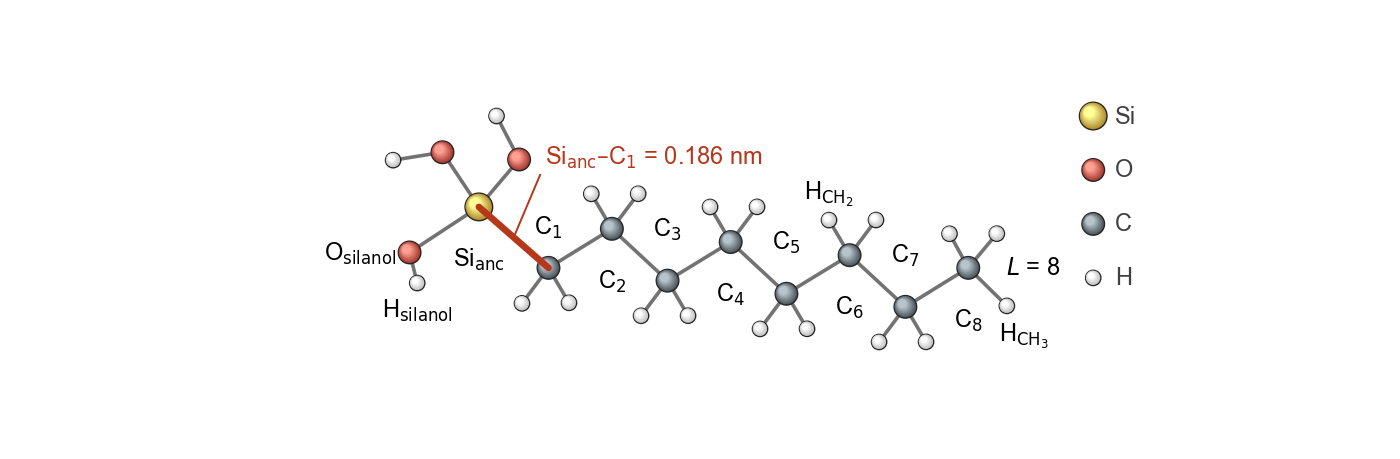

In [3]:
show_drawing('molecule')

<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Viewer 1.** The optimization steps of the ORCA relaxation (run the cell; turn and zoom with the mouse) [8, 9].

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code shows Viewer 1, the optimization steps of the ORCA relaxation in a 3D player.</div>

In [ ]:
show_structures([RELAXED / 'octylsilanetriol_trj.xyz'], 'step')

<div style="box-sizing:border-box; width:calc(100% - 40px);">

The Si<sub>anc</sub>–C<sub>1</sub> bond in the final table of the ORCA output (atoms 7 and 0, counted from 0; last column: relaxed length in Å):

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code finds the Si<sub>anc</sub>–C<sub>1</sub> bond in the final geometry table of the ORCA output and prints its length.</div>

In [5]:
lines = (RELAXED / 'octylsilanetriol.out').read_text().split('\n')
for number in range(len(lines)):
    if 'B(C   7,Si  0)' in lines[number]:
        found = number
print(f'line {found + 1} of octylsilanetriol.out:')
print(lines[found])
print(f'Si-C1 length: {float(lines[found].split()[-1]) / 10:.5f} nm, 0.186 nm in the force field')

line 3330 of octylsilanetriol.out:
     7. B(C   7,Si  0)                1.8647 -0.000003  0.0000    1.8647   
Si-C1 length: 0.18647 nm, 0.186 nm in the force field


<div style="box-sizing:border-box; width:calc(100% - 40px);">

The geometry at the Si–C bond and in the chain: the relaxed ORCA molecule against the minimum of the force-field energy of the same molecule (`force_field_energies/minimized`). Term: b₀ or θ₀ of the term of the force field.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code reads the relaxed ORCA molecule and the minimum of the force-field energy, and compares their bonds, angles and dihedrals at the Si–C bond and in the chain.</div>

In [6]:
def read_g96(path):
    """Positions (nm) of a GROMACS .g96 file."""
    lines = Path(path).read_text().split('\n')
    start = lines.index('POSITION') + 1
    xyz = []
    for line in lines[start:]:
        if line.startswith('END'):
            break
        xyz.append([float(line[24:39]), float(line[39:54]), float(line[54:69])])
    return np.array(xyz)


def distance(xyz, a, b):
    return np.linalg.norm(xyz[a] - xyz[b])


def bond_angle(xyz, a, b, c):
    u = xyz[a] - xyz[b]
    v = xyz[c] - xyz[b]
    return np.degrees(np.arccos(u @ v / np.linalg.norm(u) / np.linalg.norm(v)))


def dihedral(xyz, a, b, c, d):
    axis = (xyz[c] - xyz[b]) / np.linalg.norm(xyz[c] - xyz[b])
    u = xyz[a] - xyz[b] - ((xyz[a] - xyz[b]) @ axis) * axis
    v = xyz[d] - xyz[c] - ((xyz[d] - xyz[c]) @ axis) * axis
    return abs(np.degrees(np.arctan2(np.cross(axis, u) @ v, u @ v)))


orca = read_frames(RELAXED / 'octylsilanetriol.xyz')[0].get_positions() / 10
ff = read_g96(ENERGIES / 'minimized' / 'minimized.g96')
# atoms of the ORCA files, counted from 0
si, c1, c2, c3, c4, c5, c6 = 0, 7, 10, 13, 16, 19, 22
rows = []
rows.append(['Si_anc–C1 bond (nm)', 0.186, distance(orca, si, c1), distance(ff, si, c1)])
rows.append(['C4–C5 bond (nm)', 0.1530, distance(orca, c4, c5), distance(ff, c4, c5)])
rows.append(['Si_anc–C1–C2 angle (deg)', 113.6, bond_angle(orca, si, c1, c2), bond_angle(ff, si, c1, c2)])
rows.append(['C3–C4–C5 angle (deg)', 113.6, bond_angle(orca, c3, c4, c5), bond_angle(ff, c3, c4, c5)])
rows.append(['Si_anc–C1–C2–C3 dihedral (deg)', np.nan, dihedral(orca, si, c1, c2, c3), dihedral(ff, si, c1, c2, c3)])
rows.append(['C3–C4–C5–C6 dihedral (deg)', np.nan, dihedral(orca, c3, c4, c5, c6), dihedral(ff, c3, c4, c5, c6)])
geometry = pd.DataFrame(rows, columns=['coordinate', 'term', 'ORCA', 'force field']).set_index('coordinate')
geometry['force field − ORCA'] = geometry['force field'] - geometry['ORCA']

geometry.round(4).fillna('')

,term,ORCA,force field,force field − ORCA
coordinate,,,,
Si_anc–C1 bond (nm),0.186,0.1865,0.1859,-0.0005
C4–C5 bond (nm),0.153,0.1530,0.1535,0.0005
Si_anc–C1–C2 angle (deg),113.6,114.6568,115.7746,1.1178
C3–C4–C5 angle (deg),113.6,113.3027,112.6705,-0.6323
Si_anc–C1–C2–C3 dihedral (deg),,179.6504,179.5130,-0.1374
C3–C4–C5–C6 dihedral (deg),,179.9989,179.9348,-0.0641


<div style="box-sizing:border-box; width:calc(100% - 40px);">

- Si<sub>anc</sub>–C<sub>1</sub> is 0.1859 nm in the force field against 0.1865 nm in ORCA (b₀ = 0.186 nm).
- Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub> is 115.8° against 114.7°, 1.1° wider. In the chain, C₄–C₅ is within 0.0005 nm of ORCA and C₃–C₄–C₅ is 0.6° narrower (112.7° against 113.3°).
- Both dihedrals are trans in both methods, within 0.5° of 180°.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#3D5A80; color:#ffffff; padding:8px 14px; border-radius:6px;">Bonds<br><span style="font-size:0.72em; font-weight:normal;">the Si<sub>anc</sub>–C<sub>1</sub> bond against the C₄–C₅ bond of the chain</span></h2>

The Si–C bond of the force field (SI–CG321) has b₀ = 0.186 nm, the Si<sub>anc</sub>–C<sub>1</sub> length of the relaxed molecule, and k<sub>b</sub> = 132910 kJ mol⁻¹ nm⁻², the force constant of the CHARMM C–C bond scaled by the reduced masses of the two bonds. Two relaxed scans check it (Figure 2): the Si<sub>anc</sub>–C<sub>1</sub> bond from 0.180 to 0.194 nm, and the C₄–C₅ bond of the chain from 0.145 to 0.159 nm, whose CHARMM term (CG321–CG321: b₀ = 0.1530 nm, k<sub>b</sub> = 186188 kJ mol⁻¹ nm⁻²) [6] is the reference. At each of the 50 points of a scan the bond length is fixed and the rest of the molecule is optimized.

The minimum r₀ of a curve and its force constant k come from a cubic fit to the 9 points around its lowest point (to all points when the lowest point is at the end of the scan): k = d²E/dr² at r₀, the k of E = ½k(r − r₀)². The bond term of the force field is

$$V = \frac{1}{2}k_b\,(r - b_0)^2$$

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Figure 2.** The scanned bonds: Si<sub>anc</sub>–C<sub>1</sub> (red) and C₄–C₅ of the chain (blue). `doc/scanned_bonds.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code shows Figure 2, the fixed drawing of the two scanned bonds (<code>doc/scanned_bonds.png</code>).</div>

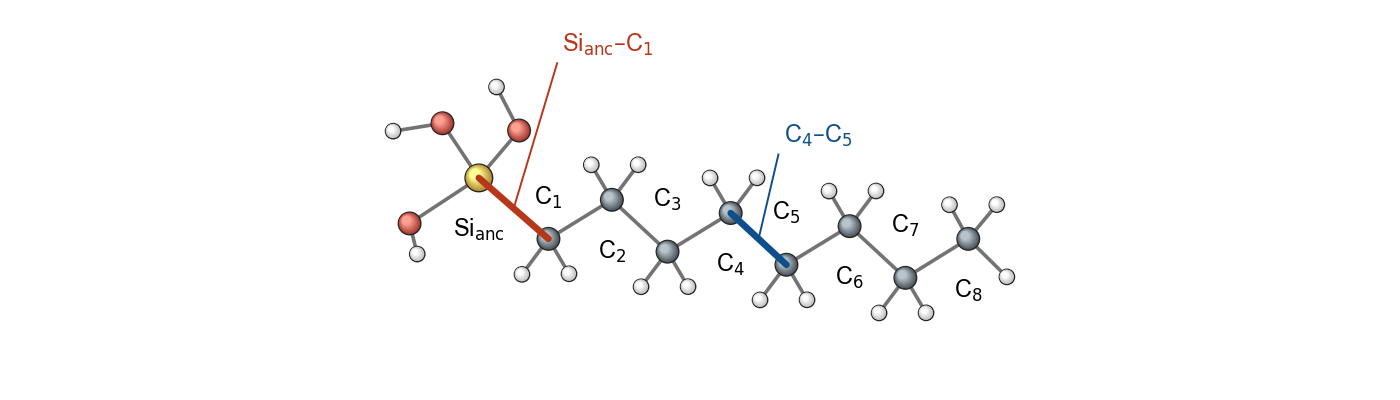

In [7]:
show_drawing('scanned_bonds')

<div style="box-sizing:border-box; width:calc(100% - 40px);">

The two bond scans of ORCA and the force-field energies of their structures:

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code defines how the scans and the force-field energies are read and how the minimum and force constant of a curve are fitted, and reads the two bond scans.</div>

In [8]:
def read_scan(path, unit=1.0):
    """Coordinate (times unit) and ORCA energy (kJ/mol, from the lowest point) of a relaxed scan (.relaxscanact.dat)."""
    coordinate, energy = np.loadtxt(path, unpack=True)
    return coordinate * unit, (energy - energy.min()) * HARTREE


def read_energies(folder):
    """Force-field energy (kJ/mol, from the lowest point) of the structures of a scan (force_field_energies)."""
    energy = np.loadtxt(ENERGIES / folder / 'potential.xvg')[:, 1]
    return energy - energy.min()


def curvature(x, e, half=4):
    """
    Minimum x0 of a curve and its curvature there, k = d2E/dx2 (the k of E = 1/2 k (x - x0)^2), from a cubic fit
    to the 2 half + 1 points around the lowest point, or to all points if the lowest point is too close to an end of
    the scan (x0 may then lie outside the scan).
    """
    low = int(np.argmin(e))
    if half <= low < len(x) - half:
        fit = np.polyfit(x[low - half:low + half + 1], e[low - half:low + half + 1], 3)
    else:
        fit = np.polyfit(x, e, 3)
    for root in np.roots(np.polyder(fit)):
        if abs(root.imag) < 1e-12 and np.polyval(np.polyder(fit, 2), root.real) > 0:
            x0 = root.real
    return x0, np.polyval(np.polyder(fit, 2), x0)


BOND_NAMES = {'Si–C': r'Si$_{\rm anc}$–C$_1$', 'C–C': r'C$_4$–C$_5$'}
BOND_COLORS = {'Si–C': SI_C_COLOR, 'C–C': CHAIN_COLOR}
bond_scans = {'Si–C': read_scan(SCANS / 'Si-C' / 'si_c_scan.relaxscanact.dat', 0.1),
              'C–C': read_scan(SCANS / 'C4-C5' / 'c4_c5_scan.relaxscanact.dat', 0.1)}
bond_energies = {'Si–C': read_energies('Si-C'), 'C–C': read_energies('C4-C5')}
for bond in bond_scans:
    r, e = bond_scans[bond]
    print(f'{bond}: {len(r)} points from {r[0]:.4f} to {r[-1]:.4f} nm, lowest ORCA point at {r[np.argmin(e)]:.5f} nm')

Si–C: 50 points from 0.1800 to 0.1940 nm, lowest ORCA point at 0.18657 nm
C–C: 50 points from 0.1450 to 0.1590 nm, lowest ORCA point at 0.15300 nm


<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Figure 3.** The bond scans of ORCA against the force-field energy of the molecule (GROMACS, at the same structures): (a) Si<sub>anc</sub>–C<sub>1</sub>, (b) C₄–C₅. `figures/bonds_force_field_energy.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code draws Figure 3 (<code>figures/bonds_force_field_energy.pdf</code>) and fits the minimum r₀ and the force constant k of every curve; it calibrates the ORCA force constant of Si–C on the CHARMM C–C bond, and the table compares ORCA and the force field.</div>

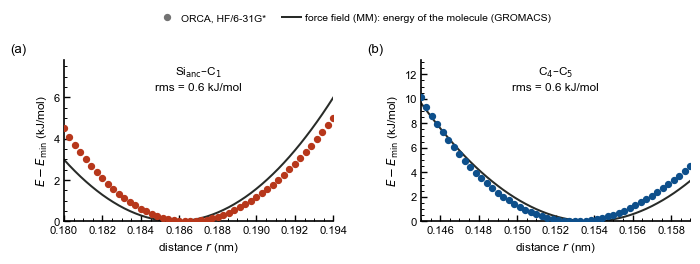

k of Si-C from the ORCA scans, calibrated on the CHARMM C-C bond: 132,117 kJ/mol/nm2 (force field 132,910, +0.6 %)


,r0 ORCA (nm),r0 force field (nm),k ORCA (kJ/mol/nm²),k force field (kJ/mol/nm²),force field / ORCA,rms (kJ/mol)
Si_anc–C1,0.18646,0.18580,196101.0,178095.0,0.91,0.65
C4–C5,0.15298,0.15383,276358.0,247646.0,0.90,0.56


In [9]:
fig, left, right = two_panels()
rows = []
for ax, bond in [(left, 'Si–C'), (right, 'C–C')]:
    r, e = bond_scans[bond]
    e_ff = bond_energies[bond]
    ax.plot(r, e, 'o', color=BOND_COLORS[bond], zorder=3)
    ax.plot(r, e_ff, color=LINE_COLOR, zorder=2)
    ax.set_xlim(r[0], r[-1])
    ax.set_ylim(0, 1.3 * max(e.max(), e_ff.max()))
    ax.set_xlabel('distance $r$ (nm)')
    ax.set_ylabel(r'$E - E_{\rm min}$ (kJ/mol)')
    ax.text(0.5, 0.97, BOND_NAMES[bond], transform=ax.transAxes, ha='center', va='top')
    ax.text(0.5, 0.86, f'rms = {rms(e_ff, e):.1f} kJ/mol', transform=ax.transAxes, ha='center', va='top')
    r0, k = curvature(r, e)
    r0_ff, k_ff = curvature(r, e_ff)
    rows.append([r0, r0_ff, k, k_ff, k_ff / k, rms(e_ff, e)])
top_legend(fig, [ORCA_ENTRY, ENERGY_ENTRY])
fig.savefig(FIGURES / 'bonds_force_field_energy.pdf')
plt.show()

bonds_energy = pd.DataFrame(rows, index=['Si_anc–C1', 'C4–C5'],
                            columns=['r0 ORCA (nm)', 'r0 force field (nm)', 'k ORCA (kJ/mol/nm²)',
                                     'k force field (kJ/mol/nm²)', 'force field / ORCA', 'rms (kJ/mol)'])
k_calibrated = bonds_energy.iloc[0, 2] * 186188.0 / bonds_energy.iloc[1, 2]
print(f'k of Si-C from the ORCA scans, calibrated on the CHARMM C-C bond: {k_calibrated:,.0f} kJ/mol/nm2 '
      f'(force field 132,910, {(132910.0 / k_calibrated - 1) * 100:+.1f} %)')
bonds_energy.round({'r0 ORCA (nm)': 5, 'r0 force field (nm)': 5, 'k ORCA (kJ/mol/nm²)': 0,
                    'k force field (kJ/mol/nm²)': 0, 'force field / ORCA': 2, 'rms (kJ/mol)': 2})

<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Force-field energy (Figure 3).** The force field follows the Si<sub>anc</sub>–C<sub>1</sub> scan as closely as the C₄–C₅ scan (rms 0.65 and 0.56 kJ mol⁻¹), with 0.91 and 0.90 of the ORCA force constant. Its minimum is 0.0007 nm below ORCA for Si<sub>anc</sub>–C<sub>1</sub> (0.1858 against 0.1865 nm) and 0.0009 nm above ORCA for C₄–C₅ (0.1538 against 0.1530 nm).
- **Force constant of the Si–C term.** HF/6-31G* overestimates force constants [10]: the k<sub>b</sub> of the CHARMM C–C bond is 0.674 of the ORCA force constant of C₄–C₅. Scaled with this factor [11], the ORCA Si–C force constant becomes 132117 kJ mol⁻¹ nm⁻², 0.6 % below the k<sub>b</sub> of the force field.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Viewer 2.** The 50 structures of the Si<sub>anc</sub>–C<sub>1</sub> (left) and C₄–C₅ (right) scans.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code shows Viewer 2, the structures of the two bond scans in 3D players.</div>

In [ ]:
show_structures([SCANS / 'Si-C' / 'si_c_scan.allxyz', SCANS / 'C4-C5' / 'c4_c5_scan.allxyz'])

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#9C4F6E; color:#ffffff; padding:8px 14px; border-radius:6px;">Angles<br><span style="font-size:0.72em; font-weight:normal;">the Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub> angle against the C₃–C₄–C₅ angle of the chain</span></h2>

Apart from the bond, the Si–C–C angle and the Si–C–C–C dihedral at the Si–C bond are taken from the CHARMM C–C–C and C–C–C–C terms [6], with the Urey–Bradley distance s₀ of the angle set for the Si–C bond (below). The Si–C–C angle (SI–CG321–CG321) is an angle term with a Urey–Bradley term on the distance s between the two outer atoms [12, 13],

$$V = \frac{1}{2}k_\theta\,(\theta-\theta_0)^2 + \frac{1}{2}k_{\rm UB}\,(s-s_0)^2, \qquad s = \sqrt{b_1^2 + b_2^2 - 2b_1b_2\cos\theta}$$

with θ₀ = 113.6°, k<sub>θ</sub> = 488.2728 kJ mol⁻¹ rad⁻², s₀ = 0.2842 nm and k<sub>UB</sub> = 9338.69 kJ mol⁻¹ nm⁻². The relaxed scans of the Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub> angle (100° to 130°) and of the C₃–C₄–C₅ angle of the chain (98° to 128°), 50 points each, check it (Figure 4). The minimum θ₀ and the force constant k of each curve come from the same cubic fits as for the bonds.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

**The Urey–Bradley distance s₀.** In CHARMM, the equilibrium values of the bonds, angles and Urey–Bradley terms are taken from the same optimized geometries [6]. For the C–C–C and C–C–H terms of the alkyl chain, s₀ is the distance between the two outer atoms with the bonds at b₀ and the angle at θ₀:

$$s_0 = \sqrt{b_1^2 + b_2^2 - 2b_1b_2\cos\theta_0}$$

The Si–C–C and Si–C–H angles keep θ₀, k<sub>θ</sub> and k<sub>UB</sub> of C–C–C and C–C–H and take s₀ from the same equation with the Si–C bond at its b₀, 0.186 nm. With b₀ and θ₀ from the topology:

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code reads b₀, θ₀ and s₀ from the topology and computes s₀ of the four angles with the equation above.</div>

In [11]:
def read_section(path, section):
    """The rows of one [ section ] of a topology, as lists of words (comments left out)."""
    rows = []
    inside = False
    for line in Path(path).read_text().split('\n'):
        line = line.split(';')[0].strip()
        if line.startswith('['):
            inside = line == f'[ {section} ]'
        elif inside and line:
            rows.append(line.split())
    return rows


b0 = {}
for i, j, func, length, kb in read_section(ENERGIES / 'octylsilanetriol.top', 'bondtypes'):
    b0[(i, j)] = b0[(j, i)] = float(length)
angle_types = {}
for i, j, k, func, theta0, k_theta, s0, k_ub in read_section(ENERGIES / 'octylsilanetriol.top', 'angletypes'):
    angle_types[(i, j, k)] = (float(theta0), float(s0))
rows = []
for i, j, k in [('CG321', 'CG321', 'CG321'), ('SI', 'CG321', 'CG321'), ('CG321', 'CG321', 'HGA2'), ('SI', 'CG321', 'HGA2')]:
    theta0, s0 = angle_types[(i, j, k)]
    b1 = b0[(i, j)]
    b2 = b0[(j, k)]
    rows.append([f'{i}–{j}–{k}', b1, b2, theta0, np.sqrt(b1 ** 2 + b2 ** 2 - 2 * b1 * b2 * np.cos(np.radians(theta0))), s0])
s0_table = pd.DataFrame(rows, columns=['angle', 'b1 (nm)', 'b2 (nm)', 'θ0 (deg)', 's0 from the equation (nm)',
                                       's0 of the force field (nm)'])
s0_table.set_index('angle').round(4)

,b1 (nm),b2 (nm),θ0 (deg),s0 from the equation (nm),s0 of the force field (nm)
angle,,,,,
CG321–CG321–CG321,0.153,0.1530,113.6,0.2560,0.2561
SI–CG321–CG321,0.186,0.1530,113.6,0.2842,0.2842
CG321–CG321–HGA2,0.153,0.1111,110.1,0.2178,0.2179
SI–CG321–HGA2,0.186,0.1111,110.1,0.2473,0.2473


<div style="box-sizing:border-box; width:calc(100% - 40px);">

- The CHARMM C–C–C and C–C–H terms match the equation: it gives their s₀, 0.2561 and 0.2179 nm, within 0.0001 nm. With the longer Si–C bond, the same equation gives s₀ = 0.2842 nm for Si–C–C and 0.2473 nm for Si–C–H.
- With these s₀, the Urey–Bradley terms are at rest when the Si–C bond is at b₀ and the angle at θ₀: the Si–C–C term has its minimum at θ₀, and the minimum of the force-field energy has Si<sub>anc</sub>–C<sub>1</sub> = 0.1859 nm (ORCA 0.1865 nm). The s₀ of C–C–C and C–C–H would be about 0.03 nm shorter than these distances and would pull the Si toward C<sub>2</sub> and the H atoms of C<sub>1</sub>, shortening the Si–C bond.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Figure 4.** The scanned angles: Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub> (red) and C₃–C₄–C₅ of the chain (blue). `doc/scanned_angles.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code shows Figure 4, the fixed drawing of the two scanned angles (<code>doc/scanned_angles.png</code>).</div>

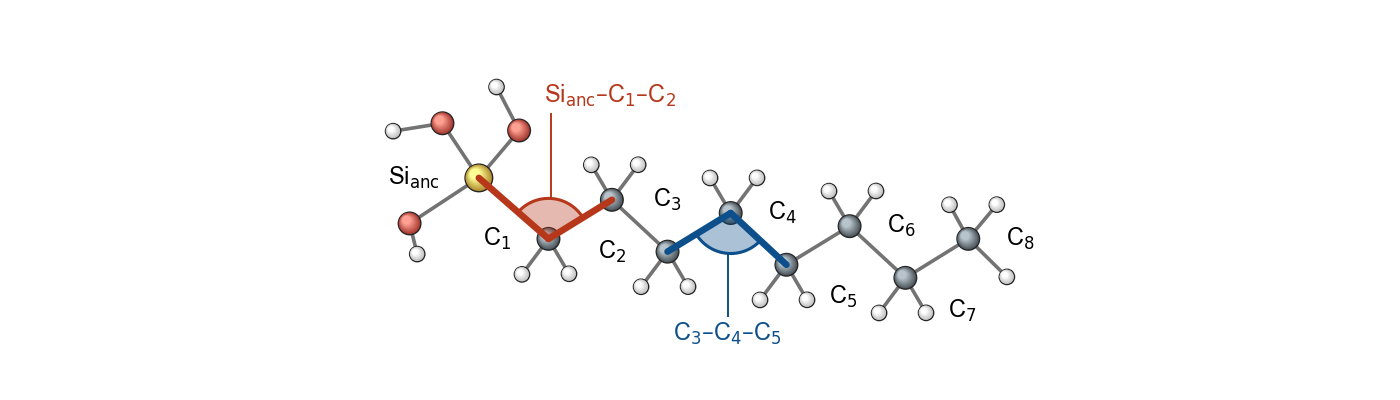

In [12]:
show_drawing('scanned_angles')

<div style="box-sizing:border-box; width:calc(100% - 40px);">

The two angle scans of ORCA and the force-field energies of their structures:

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code reads the two angle scans with their force-field energies.</div>

In [13]:
ANGLE_NAMES = {'Si–C–C': r'Si$_{\rm anc}$–C$_1$–C$_2$', 'C–C–C': r'C$_3$–C$_4$–C$_5$'}
ANGLE_COLORS = {'Si–C–C': SI_C_COLOR, 'C–C–C': CHAIN_COLOR}
angle_scans = {'Si–C–C': read_scan(SCANS / 'Si-C-C' / 'si_c_c_scan.relaxscanact.dat'),
               'C–C–C': read_scan(SCANS / 'C-C-C' / 'c_c_c_scan.relaxscanact.dat')}
angle_energies = {'Si–C–C': read_energies('Si-C-C'), 'C–C–C': read_energies('C-C-C')}
for angle in angle_scans:
    theta, e = angle_scans[angle]
    print(f'{angle}: {len(theta)} points from {theta[0]:.1f} to {theta[-1]:.1f} deg, lowest ORCA point at '
          f'{theta[np.argmin(e)]:.2f} deg')

Si–C–C: 50 points from 100.0 to 130.0 deg, lowest ORCA point at 114.69 deg
C–C–C: 50 points from 98.0 to 128.0 deg, lowest ORCA point at 113.31 deg


<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Figure 5.** The angle scans of ORCA against the force-field energy of the molecule (GROMACS, at the same structures): (a) Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub>, (b) C₃–C₄–C₅. `figures/angles_force_field_energy.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code draws Figure 5 (<code>figures/angles_force_field_energy.pdf</code>) and fits the minimum θ₀ and the force constant k of every curve.</div>

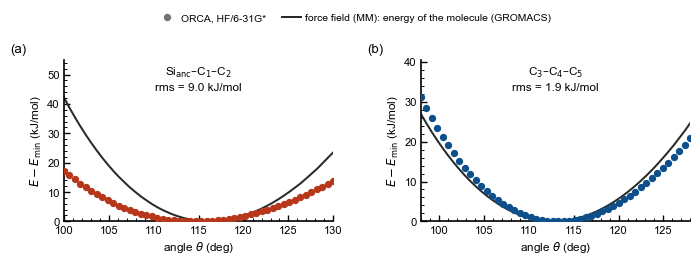

,θ0 ORCA (deg),θ0 force field (deg),k ORCA (kJ/mol/rad²),k force field (kJ/mol/rad²),force field / ORCA,rms (kJ/mol)
Si_anc–C1–C2,114.66,116.22,436.97,901.07,2.06,8.99
C3–C4–C5,113.30,112.78,719.60,732.55,1.02,1.91


In [14]:
fig, left, right = two_panels()
rows = []
for ax, angle in [(left, 'Si–C–C'), (right, 'C–C–C')]:
    theta, e = angle_scans[angle]
    e_ff = angle_energies[angle]
    ax.plot(theta, e, 'o', color=ANGLE_COLORS[angle], zorder=3)
    ax.plot(theta, e_ff, color=LINE_COLOR, zorder=2)
    ax.set_xlim(theta[0], theta[-1])
    ax.set_ylim(0, 1.3 * max(e.max(), e_ff.max()))
    ax.set_xlabel(r'angle $\theta$ (deg)')
    ax.set_ylabel(r'$E - E_{\rm min}$ (kJ/mol)')
    ax.text(0.5, 0.97, ANGLE_NAMES[angle], transform=ax.transAxes, ha='center', va='top')
    ax.text(0.5, 0.86, f'rms = {rms(e_ff, e):.1f} kJ/mol', transform=ax.transAxes, ha='center', va='top')
    theta0, k = curvature(np.radians(theta), e)
    theta0_ff, k_ff = curvature(np.radians(theta), e_ff)
    rows.append([np.degrees(theta0), np.degrees(theta0_ff), k, k_ff, k_ff / k, rms(e_ff, e)])
top_legend(fig, [ORCA_ENTRY, ENERGY_ENTRY])
fig.savefig(FIGURES / 'angles_force_field_energy.pdf')
plt.show()

angles_energy = pd.DataFrame(rows, index=['Si_anc–C1–C2', 'C3–C4–C5'],
                             columns=['θ0 ORCA (deg)', 'θ0 force field (deg)', 'k ORCA (kJ/mol/rad²)',
                                      'k force field (kJ/mol/rad²)', 'force field / ORCA', 'rms (kJ/mol)'])
angles_energy.round(2)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Force-field energy (Figure 5).** The force field has the C₃–C₄–C₅ force constant of ORCA (ratio 1.02, rms 1.9 kJ mol⁻¹), but it bends Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub> 2.06 times more stiffly than ORCA (901 against 437 kJ mol⁻¹ rad⁻², rms 9.0 kJ mol⁻¹), with its minimum along the scan 1.6° wider (116.2° against 114.7°).

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Viewer 3.** The 50 structures of the Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub> (left) and C₃–C₄–C₅ (right) scans.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code shows Viewer 3, the structures of the two angle scans in 3D players.</div>

In [ ]:
show_structures([SCANS / 'Si-C-C' / 'si_c_c_scan.allxyz', SCANS / 'C-C-C' / 'c_c_c_scan.allxyz'])

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#4F772D; color:#ffffff; padding:8px 14px; border-radius:6px;">Dihedrals<br><span style="font-size:0.72em; font-weight:normal;">the Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub>–C<sub>3</sub> rotation against the C₃–C₄–C₅–C₆ rotation of the chain</span></h2>

The Si–C–C–C dihedral of the force field (SI–CG321–CG321–CG321) has the four rows of the CHARMM C–C–C–C dihedral (CG321–CG321–CG321–CG321), which was fitted, together with the other terms of the alkanes, to quantum-chemical energies of the rotation about C–C bonds [14]:

$$V = \sum k_\phi\left[1 + \cos(n\phi - \phi_0)\right]$$

with (φ₀, k<sub>φ</sub>, n) = (0°, 0.269868 kJ mol⁻¹, 2), (180°, 0.626554 kJ mol⁻¹, 3), (0°, 0.395723 kJ mol⁻¹, 4) and (0°, 0.470742 kJ mol⁻¹, 5). The dihedral is the softest term at the Si–C bond, and it sets the trans and gauche conformations of the first carbons of the chain. The relaxed scans of the Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub>–C<sub>3</sub> and C₃–C₄–C₅–C₆ dihedrals turn them in 36 steps of 10° (Figure 6); the 37th point, the first one turned by 360°, is left out. Minima and barriers are found with a parabola through the lowest or highest point and its two neighbors.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Figure 6.** The scanned dihedrals, each a rotation about its middle bond: Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub>–C<sub>3</sub> (red) and C₃–C₄–C₅–C₆ of the chain (blue). `doc/scanned_dihedrals.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code shows Figure 6, the fixed drawing of the two scanned dihedrals (<code>doc/scanned_dihedrals.png</code>).</div>

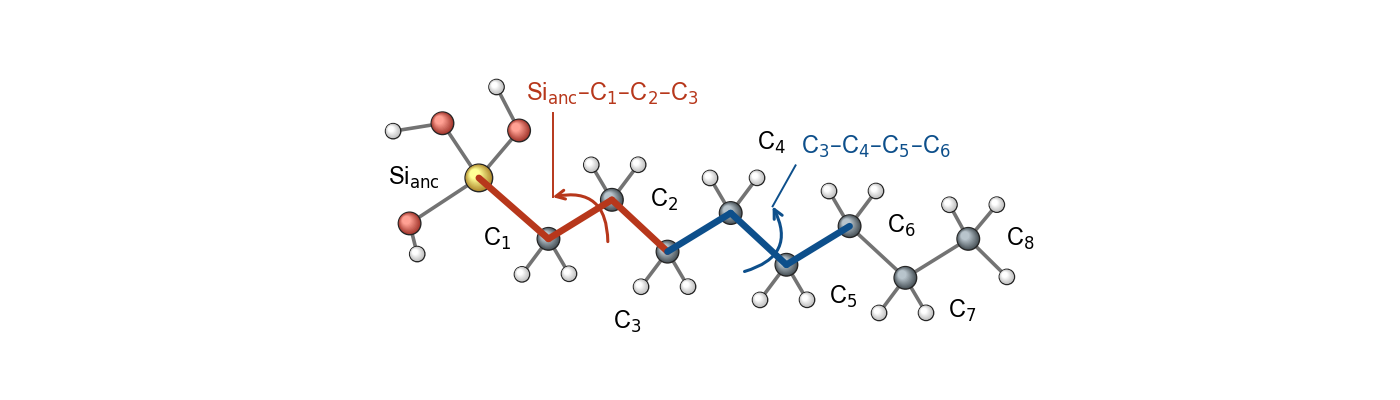

In [16]:
show_drawing('scanned_dihedrals')

<div style="box-sizing:border-box; width:calc(100% - 40px);">

The dihedral term is the softest bonded term at the Si<sub>anc</sub>–C<sub>1</sub> bond. The force field uses the CHARMM C–C–C–C term for the Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub>–C<sub>3</sub> dihedral. To check it, this dihedral was scanned from −180° to 180° in 10° steps by a relaxed scan of quantum chemistry (ORCA, HF/6-31G*). Since 180° and −180° are the same angle, the scan gives 36 structures, the 36 colored points in Figure 7 (the point at 180° repeats the one at −180°). For each structure of this scan, the potential energy of the whole molecule with the force field, a molecular mechanics (MM) model, was then computed with GROMACS (black circles in Figure 7, `force_field_energies/`). For this, `gmx mdrun -rerun` was used: it computes the energy of given structures without moving the atoms, so there is no dynamics and no energy minimization. The molecule was alone in a 10-nm box, with all atom pairs counted and no constraints. In this way, both methods give the energies of the same 36 structures, and the difference between the two curves comes only from the energy functions. Like the quantum-chemistry energy, the force-field energy is the total energy of the molecule, with the bond, angle, dihedral and non-bonded terms. Both calculations are for one molecule in the gas phase, the model molecule of Figure 1. The C₃–C₄–C₅–C₆ dihedral of the alkyl chain, whose CHARMM term is used for Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub>–C<sub>3</sub>, was scanned in the same way as a reference. Figure 7 shows the energy *E* of each scan structure relative to *E*<sub>min</sub>, the lowest of the 36 energies of the same method. *E*<sub>min</sub> is taken separately for the quantum chemistry and for the force field.

The two dihedral scans, the force-field energies of their structures, and their minima and barriers:

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code defines how the dihedral scans are read, and how their minima and barriers are found, and reads the two dihedral scans.</div>

In [17]:
def read_dihedral(folder, stem):
    """
    Dihedral (deg, -180 to 180), ORCA energy and force-field energy (kJ/mol, from the lowest point; force_field_energies)
    of a dihedral scan, in the order of the dihedral. The last point, the first one turned by 360 degrees, is left out.
    """
    phi, energy = np.loadtxt(SCANS / folder / f'{stem}.relaxscanact.dat', unpack=True)
    energy_ff = np.loadtxt(ENERGIES / folder / 'potential.xvg')[:, 1]
    phi = (phi[:-1] + 180) % 360 - 180
    order = np.argsort(phi)
    e = energy[:-1][order]
    e_ff = energy_ff[:-1][order]
    return phi[order], (e - e.min()) * HARTREE, e_ff - e_ff.min()


def stationary_point(phi, e, kind, near):
    """
    Angle and energy of the minimum or barrier (kind) within 30 degrees of near: a parabola through the lowest or
    highest point and its two neighbors.
    """
    i = None
    for j in range(len(phi)):
        if abs((phi[j] - near + 180) % 360 - 180) <= 30:
            if i is None or (kind == 'minimum' and e[j] < e[i]) or (kind == 'barrier' and e[j] > e[i]):
                i = j
    before = e[i - 1]
    after = e[(i + 1) % len(e)]
    shift = 0.5 * (before - after) / (before - 2 * e[i] + after)
    return (phi[i] + shift * (phi[1] - phi[0]) + 180) % 360 - 180, e[i] - 0.25 * (before - after) * shift


def stationary_points(phi, e):
    """Angles and energies (from the lowest of them) of the minima and barriers of a rotation."""
    angles = []
    energies = []
    for name in POINTS:
        kind, near = POINTS[name]
        angle, energy = stationary_point(phi, e, kind, near)
        angles.append(angle)
        energies.append(energy)
    return np.array(angles), np.array(energies) - min(energies)


def full_turn(phi, e):
    """The curve from -180 to 180 degrees, closed with the first and last points turned by 360 degrees."""
    return np.concatenate([[phi[-1] - 360], phi, [phi[0] + 360]]), np.concatenate([[e[-1]], e, [e[0]]])


POINTS = {'trans': ('minimum', 180), 'gauche (−)': ('minimum', -60), 'gauche (+)': ('minimum', 60),
          'trans–gauche barrier (−)': ('barrier', -120), 'trans–gauche barrier (+)': ('barrier', 120),
          'cis barrier': ('barrier', 0)}
DIHEDRAL_NAMES = {'Si–C–C–C': r'Si$_{\rm anc}$–C$_1$–C$_2$–C$_3$', 'C–C–C–C': r'C$_3$–C$_4$–C$_5$–C$_6$'}
DIHEDRAL_COLORS = {'Si–C–C–C': SI_C_COLOR, 'C–C–C–C': CHAIN_COLOR}
dihedral_scans = {'Si–C–C–C': read_dihedral('Si-C-C-C', 'si_c_c_c_scan'),
                  'C–C–C–C': read_dihedral('C-C-C-C', 'c_c_c_c_scan')}

<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Figure 7.** Relaxed scans of the dihedral angle *φ* of (a) Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub>–C<sub>3</sub> and (b) C₃–C₄–C₅–C₆ in one molecule in the gas phase (Figure 1). *E* − *E*<sub>min</sub>: energy relative to the lowest of the 36 energies of the same method. Colored points: quantum chemistry (ORCA, HF/6-31G*). Black circles, joined by a dashed line: force-field (MM) energy of the same structures, computed with GROMACS (`gmx mdrun -rerun`) without moving the atoms. rms difference: root mean square of the differences between the force-field and the quantum-chemistry energies over the 36 structures. It is zero when the two agree exactly and has no upper limit, so a smaller rms difference means a closer agreement between the force field and the quantum chemistry. `figures/dihedrals_force_field_energy.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code draws Figure 7 (<code>figures/dihedrals_force_field_energy.pdf</code>) and finds the minima and barriers of ORCA and of the force field.</div>

Si–C–C–C: minima and barriers of the force field within 4.3 deg of ORCA, rms 2.14 kJ/mol
C–C–C–C: minima and barriers of the force field within 2.2 deg of ORCA, rms 2.14 kJ/mol


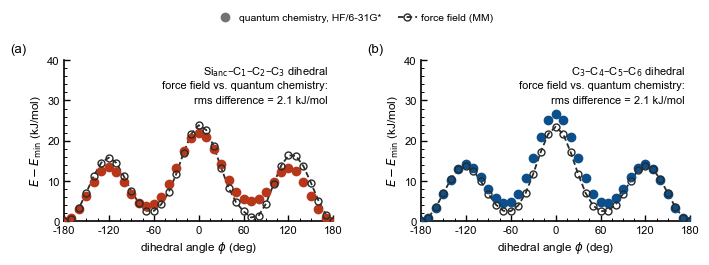

E - E_min (kJ/mol) at the minima and barriers:


Si–C–C–C             C–C–C–C            
                             ORCA force field    ORCA force field
trans                        0.00        0.00    0.00        0.00
gauche (−)                   3.89        2.46    4.41        2.39
gauche (+)                   5.05        0.95    4.41        2.39
trans–gauche barrier (−)    13.48       15.87   14.12       13.77
trans–gauche barrier (+)    13.28       16.73   14.12       13.76
cis barrier                 21.86       23.97   26.61       23.45

In [18]:
fig, left, right = two_panels()
columns = {}
for ax, dihedral_name in [(left, 'Si–C–C–C'), (right, 'C–C–C–C')]:
    phi, e, e_ff = dihedral_scans[dihedral_name]
    phi_closed, e_closed = full_turn(phi, e)
    phi_closed, e_ff_closed = full_turn(phi, e_ff)
    ax.plot(phi_closed, e_closed, 'o', ms=6.0, color=DIHEDRAL_COLORS[dihedral_name], zorder=3)
    ax.plot(phi_closed, e_ff_closed, color=LINE_COLOR, lw=1.3, ls='--', zorder=2)
    ax.plot(phi_closed, e_ff_closed, 'o', ms=5.0, mfc='none', mec=LINE_COLOR, mew=1.0, zorder=4)
    ax.set_xlim(-180, 180)
    ax.set_ylim(0, 40)
    ax.set_yticks([0, 10, 20, 30, 40])
    ax.set_xticks([-180, -120, -60, 0, 60, 120, 180])
    ax.set_xlabel(r'dihedral angle $\phi$ (deg)')
    ax.set_ylabel(r'$E - E_{\rm min}$ (kJ/mol)')
    ax.text(0.98, 0.97, f'{DIHEDRAL_NAMES[dihedral_name]} dihedral', transform=ax.transAxes, ha='right', va='top',
            fontsize=8.0)
    ax.text(0.98, 0.875, 'force field vs. quantum chemistry:', transform=ax.transAxes, ha='right', va='top', fontsize=8.0)
    ax.text(0.98, 0.78, f'rms difference = {rms(e_ff, e):.1f} kJ/mol', transform=ax.transAxes, ha='right', va='top',
            fontsize=8.0)
    angles, energies = stationary_points(phi, e)
    angles_ff, energies_ff = stationary_points(phi, e_ff)
    columns[(dihedral_name, 'ORCA')] = energies
    columns[(dihedral_name, 'force field')] = energies_ff
    shifts = np.abs((angles_ff - angles + 180) % 360 - 180)
    print(f'{dihedral_name}: minima and barriers of the force field within {shifts.max():.1f} deg of ORCA, '
          f'rms {rms(e_ff, e):.2f} kJ/mol')
top_legend(fig, [Line2D([], [], marker='o', ls='none', ms=6.0, color='0.45', label='quantum chemistry, HF/6-31G*'),
                 Line2D([], [], color=LINE_COLOR, lw=1.3, ls='--', marker='o', ms=5.0, mfc='none', mec=LINE_COLOR,
                        mew=1.0, label='force field (MM)')])
fig.savefig(FIGURES / 'dihedrals_force_field_energy.pdf')
plt.show()

dihedrals_energy = pd.DataFrame(columns, index=list(POINTS))
print('E - E_min (kJ/mol) at the minima and barriers:')
dihedrals_energy.round(2)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **Force-field energy (Figure 7).** The force field follows the Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub>–C<sub>3</sub> scan as closely as the C₃–C₄–C₅–C₆ scan, with rms differences of 2.1 kJ mol⁻¹ for both over the 36 structures, and its minima and barriers lie within 4.3° of the quantum chemistry. Its trans–gauche barriers are higher than in ORCA (15.9 and 16.7 against 13.5 and 13.3 kJ mol⁻¹), its cis barrier too (24.0 against 21.9 kJ mol⁻¹), and its gauche minima are lower (2.5 and 0.9 against 3.9 and 5.1 kJ mol⁻¹). For C₃–C₄–C₅–C₆, too, the force field puts the gauche minima below HF (2.4 against 4.4 kJ mol⁻¹); CHARMM was fitted to quantum-chemical energies at a higher level than HF [14]. Thus, the force field describes the rotation at the Si<sub>anc</sub>–C<sub>1</sub> bond as well as the rotation inside the alkyl chain, which uses the standard CHARMM term. This supports the use of the CHARMM C–C–C–C term for the Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub>–C<sub>3</sub> dihedral.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Viewer 4.** The 37 structures of the Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub>–C<sub>3</sub> (left) and C₃–C₄–C₅–C₆ (right) scans.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code shows Viewer 4, the structures of the two dihedral scans in 3D players.</div>

In [ ]:
show_structures([SCANS / 'Si-C-C-C' / 'si_c_c_c_scan.allxyz', SCANS / 'C-C-C-C' / 'c_c_c_c_scan.allxyz'])

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#6B5B95; color:#ffffff; padding:8px 14px; border-radius:6px;">Terms with oxygen<br><span style="font-size:0.72em; font-weight:normal;">the O–Si<sub>anc</sub>–C<sub>1</sub> angle, the O–Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub> dihedral and the head group</span></h2>

The terms with the OH oxygens of the head group (OSIH) take the values of CHARMM terms: CGenFF terms [6] with the Si in place of a carbon and the OH oxygens as alcohol oxygens, and the silanol terms of quartz [15]. The relaxed scans of the O–Si<sub>anc</sub>–C<sub>1</sub> angle (97° to 127°) and of the O–Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub> dihedral (36 steps of 10°) check the terms at the Si–C bond (Figure 8).

| Term | Values (nm, deg, kJ mol⁻¹ nm⁻², kJ mol⁻¹ rad⁻², kJ mol⁻¹) | Same values in CHARMM |
|---|---|---|
| SI–OSIH bond | b₀ = 0.1680, k<sub>b</sub> = 271960 | SI–OSIH (quartz) |
| OSIH–SI–CG321 angle | θ₀ = 110.1, k<sub>θ</sub> = 633.4576 | CG321–CG321–OG311 (methanol) |
| OSIH–SI–OSIH angle | θ₀ = 117.0, k<sub>θ</sub> = 251.04 | OSIH–SI–OSIH (quartz) |
| SI–OSIH–HSIO angle | θ₀ = 122.5, k<sub>θ</sub> = 284.512 | SI–OSIH–HSIO (quartz) |
| OSIH–SI–CG321–CG321, OSIH–SI–CG321–HGA2 | φ₀ = 0, k<sub>φ</sub> = 0.81588, n = 3 | CG321–CG321–CG321–OG311, OG311–CG321–CG321–HGA2 |
| HSIO–OSIH–SI–CG321 | φ₀ = 0, k<sub>φ</sub> = 4.72792, 0.58576, 1.00416, n = 1, 2, 3 | CG321–CG321–OG311–HGP1 (ethanol) |

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Figure 8.** The scanned O–Si<sub>anc</sub>–C<sub>1</sub> angle and O–Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub> dihedral. `doc/scanned_oxygen.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code shows Figure 8, the fixed drawing of the two scans with an oxygen (<code>doc/scanned_oxygen.png</code>).</div>

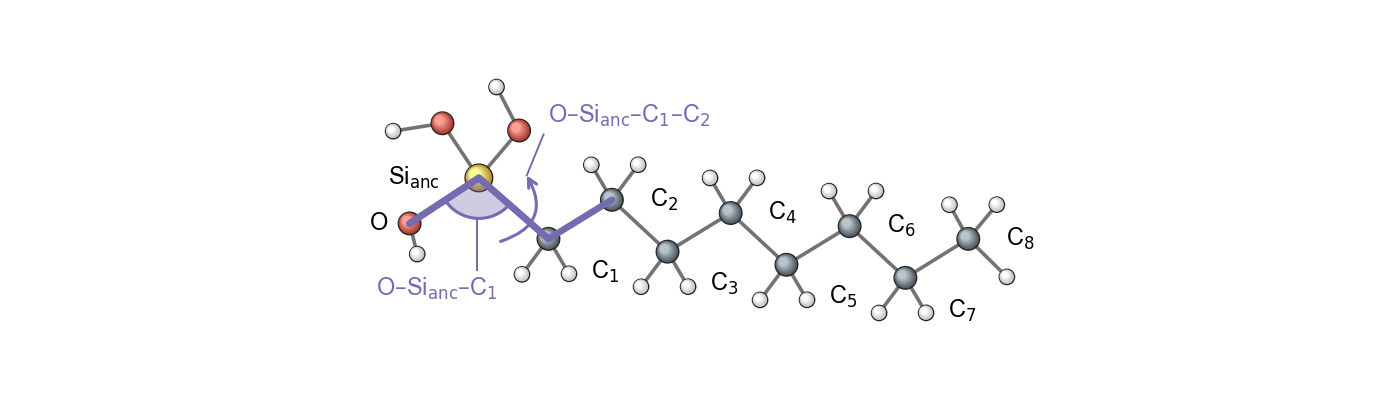

In [20]:
show_drawing('scanned_oxygen')

<div style="box-sizing:border-box; width:calc(100% - 40px);">

The two scans with an oxygen and the force-field energies of their structures:

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code reads the O–Si<sub>anc</sub>–C<sub>1</sub> angle scan and the O–Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub> dihedral scan with their force-field energies.</div>

In [21]:
o_angle, o_angle_e = read_scan(SCANS / 'O-Si-C' / 'o_si_c_scan.relaxscanact.dat')
o_angle_ff = read_energies('O-Si-C')
o_phi, o_phi_e, o_phi_ff = read_dihedral('O-Si-C-C', 'o_si_c_c_scan')
print(f'O-Si-C: {len(o_angle)} points from {o_angle[0]:.1f} to {o_angle[-1]:.1f} deg; O-Si-C-C: {len(o_phi)} points')

O-Si-C: 50 points from 97.0 to 127.0 deg; O-Si-C-C: 36 points


<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Figure 9.** The scans with an oxygen against the force-field energy of the molecule (GROMACS, at the same structures): (a) O–Si<sub>anc</sub>–C<sub>1</sub>, (b) O–Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub>. `figures/oxygen_force_field_energy.pdf`

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code draws Figure 9 (<code>figures/oxygen_force_field_energy.pdf</code>), fits the minimum and force constant of the angle and finds the minima and barriers of the dihedral.</div>

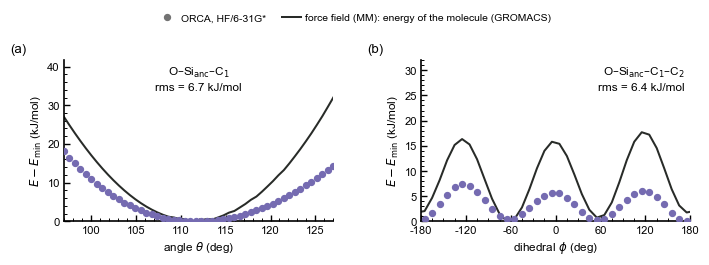

O-Si-C angle: theta0 ORCA 111.78, force field 111.71 deg; k ORCA 440, force field 751 kJ/mol/rad2 (force field / ORCA 1.71)
O-Si-C-C, E - E_min at the minima and barriers:


,φ ORCA (deg),φ force field (deg),E ORCA (kJ/mol),E force field (kJ/mol)
trans,175.32,178.30,0.00,1.74
gauche (−),-61.26,-62.35,0.41,0.00
gauche (+),57.02,57.55,0.18,0.75
trans–gauche barrier (−),-123.34,-124.77,7.40,16.41
trans–gauche barrier (+),117.38,117.98,6.05,17.87
cis barrier,-1.88,-1.84,5.72,15.98


In [22]:
fig, left, right = two_panels()
left.plot(o_angle, o_angle_e, 'o', color=OXYGEN_COLOR, zorder=3)
left.plot(o_angle, o_angle_ff, color=LINE_COLOR, zorder=2)
left.set_xlim(o_angle[0], o_angle[-1])
left.set_ylim(0, 1.3 * max(o_angle_e.max(), o_angle_ff.max()))
left.set_xlabel(r'angle $\theta$ (deg)')
left.text(0.5, 0.97, r'O–Si$_{\rm anc}$–C$_1$', transform=left.transAxes, ha='center', va='top')
left.text(0.5, 0.86, f'rms = {rms(o_angle_ff, o_angle_e):.1f} kJ/mol', transform=left.transAxes, ha='center', va='top')
phi_closed, e_closed = full_turn(o_phi, o_phi_e)
phi_closed, e_ff_closed = full_turn(o_phi, o_phi_ff)
right.plot(phi_closed, e_closed, 'o', color=OXYGEN_COLOR, zorder=3)
right.plot(phi_closed, e_ff_closed, color=LINE_COLOR, zorder=2)
right.set_xlim(-180, 180)
right.set_ylim(0, 32)
right.set_xticks([-180, -120, -60, 0, 60, 120, 180])
right.set_xlabel(r'dihedral $\phi$ (deg)')
right.text(0.98, 0.97, r'O–Si$_{\rm anc}$–C$_1$–C$_2$', transform=right.transAxes, ha='right', va='top')
right.text(0.98, 0.86, f'rms = {rms(o_phi_ff, o_phi_e):.1f} kJ/mol', transform=right.transAxes, ha='right', va='top')
for ax in (left, right):
    ax.set_ylabel(r'$E - E_{\rm min}$ (kJ/mol)')
top_legend(fig, [ORCA_ENTRY, ENERGY_ENTRY])
fig.savefig(FIGURES / 'oxygen_force_field_energy.pdf')
plt.show()

theta0, k = curvature(np.radians(o_angle), o_angle_e)
theta0_ff, k_ff = curvature(np.radians(o_angle), o_angle_ff)
oxygen_angle = {'θ0 ORCA (deg)': np.degrees(theta0), 'θ0 force field (deg)': np.degrees(theta0_ff),
                'k ORCA (kJ/mol/rad²)': k, 'k force field (kJ/mol/rad²)': k_ff}
print(f'O-Si-C angle: theta0 ORCA {np.degrees(theta0):.2f}, force field {np.degrees(theta0_ff):.2f} deg; k ORCA {k:.0f}, '
      f'force field {k_ff:.0f} kJ/mol/rad2 (force field / ORCA {k_ff / k:.2f})')
angles, energies = stationary_points(o_phi, o_phi_e)
angles_ff, energies_ff = stationary_points(o_phi, o_phi_ff)
oxygen_energy = pd.DataFrame({'φ ORCA (deg)': angles, 'φ force field (deg)': angles_ff,
                              'E ORCA (kJ/mol)': energies, 'E force field (kJ/mol)': energies_ff}, index=list(POINTS))
print('O-Si-C-C, E - E_min at the minima and barriers:')
oxygen_energy.round(2)

<div style="box-sizing:border-box; width:calc(100% - 40px);">

The geometry of the head group: the relaxed ORCA molecule against the minimum of the force-field energy (smallest to largest of the three bonds or angles of each kind), and the force constants of the Si–O bonds from the Hessian of the ORCA frequency calculation, projected on each bond [16] and calibrated on the CHARMM C–C bond as the bond scans (the C–C bonds C₂–C₃ to C₆–C₇) [11].

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code compares the head group of the relaxed ORCA molecule with the force-field minimum, and gets the Si–O force constants from the ORCA Hessian, calibrated on the CHARMM C–C bond.</div>

In [23]:
def read_hessian(path):
    """Hessian (Hartree/Bohr^2), elements and positions (Bohr) of an ORCA .hess file."""
    lines = Path(path).read_text().split('\n')
    i = lines.index('$hessian') + 1
    n = int(lines[i])
    hessian = np.zeros((n, n))
    i = i + 1
    while True:
        columns = []
        for x in lines[i].split():
            columns.append(int(x))
        for row in range(n):
            values = lines[i + 1 + row].split()
            for j in range(len(columns)):
                hessian[int(values[0]), columns[j]] = float(values[1 + j])
        i = i + n + 1
        if columns[-1] == n - 1:
            break
    j = lines.index('$atoms') + 1
    xyz = []
    for a in range(int(lines[j])):
        parts = lines[j + 1 + a].split()
        xyz.append([float(parts[2]), float(parts[3]), float(parts[4])])
    return hessian, np.array(xyz)


def projected_force_constant(hessian, xyz, a, b):
    """Force constant (kJ/mol/nm2) of the bond a-b: the Hessian block of the two atoms projected on the bond."""
    block = -hessian[3 * a:3 * a + 3, 3 * b:3 * b + 3]
    values, vectors = np.linalg.eig(block)
    direction = (xyz[b] - xyz[a]) / np.linalg.norm(xyz[b] - xyz[a])
    k = 0
    for i in range(3):
        k = k + values[i].real * abs(direction @ vectors[:, i].real)
    return k * HARTREE / BOHR ** 2


oxygens = [1, 2, 5]
rows = []
for name, term, pairs in [('Si–O bond (nm)', 0.1680, [(si, 1), (si, 2), (si, 5)]),
                          ('O–H bond (nm)', 0.0975, [(1, 3), (2, 4), (5, 6)])]:
    values_orca = []
    values_ff = []
    for a, b in pairs:
        values_orca.append(distance(orca, a, b))
        values_ff.append(distance(ff, a, b))
    rows.append([name, term, min(values_orca), max(values_orca), min(values_ff), max(values_ff)])
for name, term, triples in [('O–Si–O angle (deg)', 117.0, [(1, si, 2), (1, si, 5), (2, si, 5)]),
                            ('O–Si–C1 angle (deg)', 110.1, [(1, si, c1), (2, si, c1), (5, si, c1)]),
                            ('Si–O–H angle (deg)', 122.5, [(si, 1, 3), (si, 2, 4), (si, 5, 6)])]:
    values_orca = []
    values_ff = []
    for a, b, c in triples:
        values_orca.append(bond_angle(orca, a, b, c))
        values_ff.append(bond_angle(ff, a, b, c))
    rows.append([name, term, min(values_orca), max(values_orca), min(values_ff), max(values_ff)])
head_group = pd.DataFrame(rows, columns=['coordinate', 'term', 'ORCA, smallest', 'ORCA, largest',
                                         'force field, smallest', 'force field, largest']).set_index('coordinate')
display(head_group.round(4))

hessian, xyz = read_hessian(RELAXED / 'octylsilanetriol.hess')
inner = []
for a, b in [(c2, c3), (c3, c4), (c4, c5), (c5, c6), (c6, 25)]:
    inner.append(projected_force_constant(hessian, xyz, a, b))
factor = 186188.0 / np.mean(inner)
rows = []
for o in oxygens:
    k = projected_force_constant(hessian, xyz, si, o)
    rows.append([f'Si–O{o}', k, k * factor])
print(f'calibration: CHARMM C-C 186,188 / Hessian C-C {np.mean(inner):,.0f} = {factor:.3f}; '
      'force field: SI-OSIH 271,960 kJ/mol/nm2')
pd.DataFrame(rows, columns=['bond', 'k, Hessian (kJ/mol/nm²)', 'k, calibrated (kJ/mol/nm²)']).set_index('bond').round(0)

,term,"ORCA, smallest","ORCA, largest","force field, smallest","force field, largest"
coordinate,,,,,
Si–O bond (nm),0.1680,0.1640,0.1649,0.1656,0.1657
O–H bond (nm),0.0975,0.0947,0.0948,0.0971,0.0972
O–Si–O angle (deg),117.0000,103.8564,111.7024,107.4907,110.6495
O–Si–C1 angle (deg),110.1000,106.8130,113.2718,109.6096,109.9799
Si–O–H angle (deg),122.5000,116.2773,118.3999,118.7478,118.8307


calibration: CHARMM C-C 186,188 / Hessian C-C 212,447 = 0.876; force field: SI-OSIH 271,960 kJ/mol/nm2


,"k, Hessian (kJ/mol/nm²)","k, calibrated (kJ/mol/nm²)"
bond,,
Si–O1,287571.0,252027.0
Si–O2,289104.0,253370.0
Si–O5,274146.0,240261.0


<div style="box-sizing:border-box; width:calc(100% - 40px);">

- **O–Si<sub>anc</sub>–C<sub>1</sub>.** The force field has the minimum of ORCA within 0.1° (111.7° against 111.8°) but is 1.71 times stiffer (751 against 440 kJ mol⁻¹ rad⁻², rms 6.7 kJ mol⁻¹; Figure 9).
- **O–Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub>.** The force field has the three minima of ORCA within 3°, but barriers of 16.0–17.9 kJ mol⁻¹ against 5.7–7.4 kJ mol⁻¹ (Figure 9): the nine threefold terms about the Si–C bond (three O–Si–C–C and six O–Si–C–H, 0.81588 kJ mol⁻¹ each) add up in phase.
- **Head group.** Si–O is 0.1656–0.1657 nm in the force field against 0.1640–0.1649 nm in ORCA (b₀ = 0.1680 nm), and O–H 0.0971–0.0972 nm against 0.0947–0.0948 nm (b₀ = 0.0975 nm). The calibrated Hessian gives 240000–253000 kJ mol⁻¹ nm⁻² for Si–O, against 271960 for SI–OSIH. In both methods the angles of the head group lie far from the θ₀ of OSIH–SI–OSIH (117.0°) and SI–OSIH–HSIO (122.5°), as the other terms of the head group set them: O–Si–O 107.5–110.6° against 103.9–111.7°, Si–O–H 118.7–118.8° against 116.3–118.4°.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

**Viewer 5.** The 50 structures of the O–Si<sub>anc</sub>–C<sub>1</sub> scan (left) and the 37 of the O–Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub> scan (right).

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code shows Viewer 5, the structures of the two scans with an oxygen in 3D players.</div>

In [ ]:
show_structures([SCANS / 'O-Si-C' / 'o_si_c_scan.allxyz', SCANS / 'O-Si-C-C' / 'o_si_c_c_scan.allxyz'])

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#37474F; color:#ffffff; padding:8px 14px; border-radius:6px;">Summary<br><span style="font-size:0.72em; font-weight:normal;">how far the force field is from ORCA</span></h2>

Bonds and angles: the minimum of the relaxed molecule (ORCA → force field), the force constant of the force-field energy against ORCA, and the rms difference between the scan and the force-field energy. Dihedrals: the energies of the gauche minima and of the barriers (ORCA → force field) and the same rms difference.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code collects the results of all scans in the two summary tables: bonds and angles, and dihedrals.</div>

In [25]:
rows = []
names = [('Si_anc–C1 bond', [si, c1], bonds_energy, 0, ' nm', 4),
         ('C4–C5 bond (chain)', [c4, c5], bonds_energy, 1, ' nm', 4),
         ('Si_anc–C1–C2 angle', [si, c1, c2], angles_energy, 0, '°', 1),
         ('C3–C4–C5 angle (chain)', [c3, c4, c5], angles_energy, 1, '°', 1),
         ('O–Si_anc–C1 angle', [OXYGEN, si, c1], None, 0, '°', 1)]
for name, atoms, energy_table, position, unit, digits in names:
    values = []
    for xyz in [orca, ff]:
        if len(atoms) == 2:
            values.append(distance(xyz, atoms[0], atoms[1]))
        else:
            values.append(bond_angle(xyz, atoms[0], atoms[1], atoms[2]))
    relaxed = f'{values[0]:.{digits}f} → {values[1]:.{digits}f}{unit}'
    if energy_table is None:
        ratio = oxygen_angle['k force field (kJ/mol/rad²)'] / oxygen_angle['k ORCA (kJ/mol/rad²)']
        rms_energy = rms(o_angle_ff, o_angle_e)
    else:
        ratio = energy_table.iloc[position, 4]
        rms_energy = energy_table.iloc[position, 5]
    rows.append([name, relaxed, ratio, rms_energy])
bonds_and_angles = pd.DataFrame(rows, columns=['coordinate', 'relaxed, ORCA → force field', 'k, force field / ORCA',
                                               'rms (kJ/mol)'])
display(bonds_and_angles.set_index('coordinate').round(2))

rows = []
for dihedral_name, label in [('Si–C–C–C', 'Si_anc–C1–C2–C3'), ('C–C–C–C', 'C3–C4–C5–C6 (chain)')]:
    phi, e, e_ff = dihedral_scans[dihedral_name]
    orca_e = dihedrals_energy[(dihedral_name, 'ORCA')]
    ff_e = dihedrals_energy[(dihedral_name, 'force field')]
    rows.append([label, f'{orca_e.iloc[1]:.1f}, {orca_e.iloc[2]:.1f} → {ff_e.iloc[1]:.1f}, {ff_e.iloc[2]:.1f}',
                 f'{orca_e.iloc[3]:.1f}, {orca_e.iloc[4]:.1f} → {ff_e.iloc[3]:.1f}, {ff_e.iloc[4]:.1f}',
                 f'{orca_e.iloc[5]:.1f} → {ff_e.iloc[5]:.1f}', rms(e_ff, e)])
rows.append(['O–Si_anc–C1–C2', f'{oxygen_energy.iloc[1, 2]:.1f}, {oxygen_energy.iloc[2, 2]:.1f} → '
             f'{oxygen_energy.iloc[1, 3]:.1f}, {oxygen_energy.iloc[2, 3]:.1f}',
             f'{oxygen_energy.iloc[3, 2]:.1f}, {oxygen_energy.iloc[4, 2]:.1f} → '
             f'{oxygen_energy.iloc[3, 3]:.1f}, {oxygen_energy.iloc[4, 3]:.1f}',
             f'{oxygen_energy.iloc[5, 2]:.1f} → {oxygen_energy.iloc[5, 3]:.1f}',
             rms(o_phi_ff, o_phi_e)])
dihedrals = pd.DataFrame(rows, columns=['dihedral', 'gauche (−), (+), ORCA → force field (kJ/mol)',
                                        'trans–gauche barriers (−), (+) (kJ/mol)', 'cis barrier (kJ/mol)',
                                        'rms (kJ/mol)'])
dihedrals.set_index('dihedral').round(2)

,"relaxed, ORCA → force field","k, force field / ORCA",rms (kJ/mol)
coordinate,,,
Si_anc–C1 bond,0.1865 → 0.1859 nm,0.91,0.65
C4–C5 bond (chain),0.1530 → 0.1535 nm,0.90,0.56
Si_anc–C1–C2 angle,114.7 → 115.8°,2.06,8.99
C3–C4–C5 angle (chain),113.3 → 112.7°,1.02,1.91
O–Si_anc–C1 angle,111.8 → 109.6°,1.71,6.70


,"gauche (−), (+), ORCA → force field (kJ/mol)","trans–gauche barriers (−), (+) (kJ/mol)",cis barrier (kJ/mol),rms (kJ/mol)
dihedral,,,,
Si_anc–C1–C2–C3,"3.9, 5.1 → 2.5, 0.9","13.5, 13.3 → 15.9, 16.7",21.9 → 24.0,2.14
C3–C4–C5–C6 (chain),"4.4, 4.4 → 2.4, 2.4","14.1, 14.1 → 13.8, 13.8",26.6 → 23.5,2.14
O–Si_anc–C1–C2,"0.4, 0.2 → 0.0, 0.7","7.4, 6.0 → 16.4, 17.9",5.7 → 16.0,6.37


<div style="box-sizing:border-box; width:calc(100% - 40px);">

1. **Equilibrium geometry.** At the Si–C bond the force field gives Si<sub>anc</sub>–C<sub>1</sub> within 0.0006 nm of ORCA (0.1859 against 0.1865 nm), with the Urey–Bradley s₀ at C<sub>1</sub> set for the Si–C bond, and Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub> 1.1° wider. In the chain the force field is within 0.0005 nm and 0.6° of ORCA.
2. **Bond and angle.** The Si–C bond term has the force constant that ORCA gives when calibrated on the CHARMM C–C bond (0.6 % apart), and along the scans the force field has 0.91 of the ORCA stiffness for Si–C and 0.90 for C–C. The Si<sub>anc</sub>–C<sub>1</sub>–C<sub>2</sub> angle is 2.06 times stiffer than ORCA, while C₃–C₄–C₅ matches (1.02).
3. **Dihedral.** The rotation about C<sub>1</sub>–C<sub>2</sub> is as close to ORCA as the rotation about a C–C bond of the chain (rms 2.1 kJ mol⁻¹ for both), with its minima and barriers at the angles of ORCA within 5°. The force field puts the gauche minima below HF for both rotations, at the Si–C bond by 1.4 and 4.1 kJ mol⁻¹ and in the chain by 2.0 kJ mol⁻¹.
4. **Terms with oxygen.** The O–Si–C angle has the minimum of ORCA and is 1.7 times stiffer, and the O–Si–C–C barriers are two to three times those of ORCA.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#005F73; color:#ffffff; padding:8px 14px; border-radius:6px;">Force field<br><span style="font-size:0.72em; font-weight:normal;">all parameters of the monolayers on silica in water</span></h2>

The force field of the alkylsilane monolayers on silica in water has 14 atom types: CHARMM [5] with the CGenFF atom types [6] for the alkyl chain and the silanol atom types [15] for the OH groups on Si<sub>anc</sub>, the INTERFACE force field of silica [17] and CHARMM TIP3P water [13, 18]. The terms at the Si–C bond and at the bridge to the silica join them. All parameters are in one GROMACS force-field folder, `GROMACS_force_field/alkylsilane_silica.ff`, written from the files in `ForceField` by `make_force_field.py`, and the tables below are read from it. The energy of the force field is

$$V_{\rm bonded} = \sum_{\rm bonds}\frac{1}{2}k_b\,(b-b_0)^2 + \sum_{\rm angles}\left[\frac{1}{2}k_\theta\,(\theta-\theta_0)^2 + \frac{1}{2}k_{\rm UB}\,(s-s_0)^2\right] + \sum_{\rm dihedrals}k_\phi\left[1+\cos(n\phi-\phi_0)\right]$$

$$V_{\rm nonbonded} = \sum_{i<j}\left\{4\varepsilon_{ij}\left[\left(\frac{\sigma_{ij}}{r_{ij}}\right)^{12}-\left(\frac{\sigma_{ij}}{r_{ij}}\right)^{6}\right]+\frac{q_iq_j}{4\pi\varepsilon_0\,r_{ij}}\right\}$$

with the bond lengths b, the angles θ, the Urey–Bradley distances s, the dihedrals φ and the distances r<sub>ij</sub> between atoms. Two atoms of types i and j have σ<sub>ij</sub> = (σ<sub>i</sub> + σ<sub>j</sub>)/2 and ε<sub>ij</sub> = (ε<sub>i</sub>ε<sub>j</sub>)<sup>1/2</sup>. The nonbonded sum runs over the atoms of different molecules, the atoms more than three bonds apart and the 1–4 pairs (three bonds apart) at full strength; the 1–4 pairs of the pair table have their own σ and ε. The charge of each atom type is its charge in the monolayers and in TIP3P water. The last column of each table gives the force field that the parameter comes from.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code reads the force field from <code>GROMACS_force_field/alkylsilane_silica.ff</code> and shows the atom types and the 1–4 pairs.</div>

In [26]:
FORCE_FIELD = Path('GROMACS_force_field/alkylsilane_silica.ff')
# the force field of each block of alkylsilane_silica.ff, from the comment line above the block
SOURCES = {'CHARMM36': 'CHARMM36', 'INTERFACE': 'INTERFACE silica', 'the terms at the Si-C bond': 'Si–C bond and bridge'}
ATOM_NAMES = {'CG321': 'C of CH₂', 'CG331': 'C of CH₃', 'HGA2': 'H of CH₂', 'HGA3': 'H of CH₃', 'SI': 'Si_anc',
              'OSIH': 'O of OH on Si_anc', 'HSIO': 'H of OH on Si_anc', 'ISC4': 'Si of silica',
              'IOC23': 'O of Si–O–Si in silica', 'IOC24': 'O of a silanol of silica',
              'IOC25': 'O of the bridge, silica–O–Si_anc', 'IHOY': 'H of a silanol of silica', 'OT': 'O of water',
              'HT': 'H of water'}


def read_force_field(name, section):
    """The rows of one [ section ] of a file of alkylsilane_silica.ff, as lists of words with the force field last."""
    rows = []
    inside = False
    source = None
    for line in (FORCE_FIELD / name).read_text().split('\n'):
        if line.startswith('['):
            inside = line == f'[ {section} ]'
        elif inside and line.startswith(';'):
            for start, label in SOURCES.items():
                if line.startswith('; ' + start):
                    source = label
        elif inside and line.strip():
            rows.append(line.split() + [source])
    return rows


rows = []
for name, number, mass, charge, ptype, sigma, epsilon, source in read_force_field('ffnonbonded.itp', 'atomtypes'):
    rows.append([name, ATOM_NAMES[name], float(mass), float(charge), float(sigma), float(epsilon), source])
atom_type_table = pd.DataFrame(rows, columns=['type', 'atom', 'mass (u)', 'charge (e)', 'σ (nm)', 'ε (kJ/mol)',
                                              'force field'])
display(atom_type_table.set_index('type').round(6))
rows = []
for i, j, func, sigma, epsilon, source in read_force_field('ffnonbonded.itp', 'pairtypes'):
    rows.append([f'{i}–{j}', float(sigma), float(epsilon), source])
pair_table = pd.DataFrame(rows, columns=['1–4 pair', 'σ (nm)', 'ε (kJ/mol)', 'force field'])
pair_table.set_index('1–4 pair').round(6)

,atom,mass (u),charge (e),σ (nm),ε (kJ/mol),force field
type,,,,,,
CG321,C of CH₂,12.0110,-0.180,0.358141,0.234304,CHARMM36
CG331,C of CH₃,12.0110,-0.270,0.365268,0.326352,CHARMM36
HGA2,H of CH₂,1.0080,0.090,0.238761,0.146440,CHARMM36
HGA3,H of CH₃,1.0080,0.090,0.238761,0.100416,CHARMM36
SI,Si_anc,28.0855,0.760,0.391995,2.510400,CHARMM36
OSIH,O of OH on Si_anc,15.9990,-0.510,0.315378,0.636386,CHARMM36
HSIO,H of OH on Si_anc,1.0080,0.320,0.040001,0.192464,CHARMM36
OT,O of water,15.9994,-0.834,0.315057,0.636386,CHARMM36
HT,H of water,1.0080,0.417,0.040001,0.192464,CHARMM36


,σ (nm),ε (kJ/mol),force field
1–4 pair,,,
CG321–CG321,0.338542,0.041840,CHARMM36
CG321–CG331,0.338542,0.041840,CHARMM36
CG321–HGA2,0.288651,0.078275,CHARMM36
CG321–HGA3,0.288651,0.064818,CHARMM36
CG321–HSIO,0.189271,0.089737,CHARMM36
CG321–HT,0.189271,0.089737,CHARMM36
CG321–OSIH,0.326960,0.163176,CHARMM36
CG321–OT,0.326799,0.163176,CHARMM36
CG321–SI,0.365268,0.324091,CHARMM36


<div style="box-sizing:border-box; width:calc(100% - 40px);">

The bonded terms: bonds, angles with their Urey–Bradley terms, and dihedrals. A dihedral with several rows is the sum of their terms.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code shows the bonds, the angles and the dihedrals of the force field.</div>

In [27]:
rows = []
for i, j, func, b0, kb, source in read_force_field('ffbonded.itp', 'bondtypes'):
    rows.append([f'{i}–{j}', float(b0), float(kb), source])
bond_table = pd.DataFrame(rows, columns=['bond', 'b0 (nm)', 'kb (kJ/mol/nm²)', 'force field'])
display(bond_table.set_index('bond').round(6))
rows = []
for i, j, k, func, theta0, k_theta, s0, k_ub, source in read_force_field('ffbonded.itp', 'angletypes'):
    rows.append([f'{i}–{j}–{k}', float(theta0), float(k_theta), float(s0), float(k_ub), source])
angle_table = pd.DataFrame(rows, columns=['angle', 'θ0 (deg)', 'kθ (kJ/mol/rad²)', 's0 (nm)', 'kUB (kJ/mol/nm²)',
                                          'force field'])
display(angle_table.set_index('angle').round(6))
rows = []
for i, j, k, l, func, phi0, k_phi, n, source in read_force_field('ffbonded.itp', 'dihedraltypes'):
    rows.append([f'{i}–{j}–{k}–{l}', float(phi0), float(k_phi), int(n), source])
dihedral_table = pd.DataFrame(rows, columns=['dihedral', 'φ0 (deg)', 'kφ (kJ/mol)', 'n', 'force field'])
dihedral_table.set_index('dihedral').round(6)

,b0 (nm),kb (kJ/mol/nm²),force field
bond,,,
CG321–CG321,0.15300,186188.0,CHARMM36
CG321–CG331,0.15280,186188.0,CHARMM36
CG321–HGA2,0.11110,258571.2,CHARMM36
CG331–CG331,0.15300,186188.0,CHARMM36
CG331–HGA3,0.11110,269449.6,CHARMM36
SI–OSIH,0.16800,271960.0,CHARMM36
HSIO–OSIH,0.09750,473628.8,CHARMM36
HT–HT,0.15139,0.0,CHARMM36
HT–OT,0.09572,376560.0,CHARMM36


,θ0 (deg),kθ (kJ/mol/rad²),s0 (nm),kUB (kJ/mol/nm²),force field
angle,,,,,
CG321–CG321–CG321,113.60,488.2728,0.2561,9338.69,CHARMM36
CG321–CG321–CG331,115.00,485.3440,0.2561,6694.40,CHARMM36
CG321–CG321–HGA2,110.10,221.7520,0.2179,18853.10,CHARMM36
CG331–CG321–CG331,114.00,446.4328,0.2561,6694.40,CHARMM36
CG331–CG321–HGA2,110.10,289.5328,0.2179,18853.10,CHARMM36
HGA2–CG321–HGA2,109.00,297.0640,0.1802,4518.72,CHARMM36
CG321–CG331–HGA3,110.10,289.5328,0.2179,18853.10,CHARMM36
CG331–CG331–HGA3,110.10,313.8000,0.2179,18853.10,CHARMM36
HGA3–CG331–HGA3,108.40,297.0640,0.1802,4518.72,CHARMM36


,φ0 (deg),kφ (kJ/mol),n,force field
dihedral,,,,
CG321–CG321–CG321–CG321,0.0,0.269868,2,CHARMM36
CG321–CG321–CG321–CG321,180.0,0.626554,3,CHARMM36
CG321–CG321–CG321–CG321,0.0,0.395723,4,CHARMM36
CG321–CG321–CG321–CG321,0.0,0.470742,5,CHARMM36
CG321–CG321–CG321–CG331,0.0,0.629734,2,CHARMM36
CG321–CG321–CG321–CG331,180.0,0.340285,3,CHARMM36
CG321–CG321–CG321–CG331,0.0,0.452876,4,CHARMM36
CG321–CG321–CG321–CG331,0.0,0.853159,5,CHARMM36
CG321–CG321–CG321–HGA2,0.0,0.815880,3,CHARMM36


<div style="box-sizing:border-box; width:calc(100% - 40px);">

The water molecule, TIP3P, is rigid (SETTLE): the CHARMM HT–OT and HT–HT bonds and the HT–OT–HT angle in the tables above are not used.

</div>

<div style="box-sizing:border-box; width:calc(100% - 40px); background-color:#FFF7D6; color:#3B3B3B; padding:6px 12px; border-radius:6px;">The following code shows the atoms of the TIP3P water molecule and its fixed geometry.</div>

In [28]:
rows = []
for nr, kind, resnr, residue, atom, cgnr, charge, mass in read_section(FORCE_FIELD / 'tip3p.itp', 'atoms'):
    rows.append([atom, kind, float(charge), float(mass)])
water_table = pd.DataFrame(rows, columns=['atom', 'type', 'charge (e)', 'mass (u)'])
display(water_table.set_index('atom'))
ow, funct, d_oh, d_hh = read_section(FORCE_FIELD / 'tip3p.itp', 'settles')[0]
angle_hoh = 2 * np.degrees(np.arcsin(float(d_hh) / 2 / float(d_oh)))
print(f'SETTLE: O–H {float(d_oh):.5f} nm and H–H {float(d_hh):.5f} nm, so H–O–H {angle_hoh:.2f}°')

,type,charge (e),mass (u)
atom,,,
OH2,OT,-0.834,15.9994
H1,HT,0.417,1.0080
H2,HT,0.417,1.0080


SETTLE: O–H 0.09572 nm and H–H 0.15139 nm, so H–O–H 104.52°


<div style="box-sizing:border-box; width:calc(100% - 40px);">

<h2 style="background-color:#6C757D; color:#ffffff; padding:8px 14px; border-radius:6px;">References</h2>

1. F. Neese, *WIREs Comput. Mol. Sci.* **12**, e1606 (2022).
2. F. Neese, F. Wennmohs, U. Becker, C. Riplinger, *J. Chem. Phys.* **152**, 224108 (2020).
3. W. J. Hehre, R. Ditchfield, J. A. Pople, *J. Chem. Phys.* **56**, 2257–2261 (1972).
4. P. C. Hariharan, J. A. Pople, *Theor. Chim. Acta* **28**, 213–222 (1973).
5. B. R. Brooks et al., *J. Comput. Chem.* **30**, 1545–1614 (2009).
6. K. Vanommeslaeghe et al., *J. Comput. Chem.* **31**, 671–690 (2010).
7. M. J. Abraham, T. Murtola, R. Schulz, S. Páll, J. C. Smith, B. Hess, E. Lindahl, *SoftwareX* **1–2**, 19–25 (2015).
8. H. Nguyen, D. A. Case, A. S. Rose, *Bioinformatics* **34**, 1241–1242 (2018).
9. A. H. Larsen et al., *J. Phys.: Condens. Matter* **29**, 273002 (2017).
10. A. P. Scott, L. Radom, *J. Phys. Chem.* **100**, 16502–16513 (1996).
11. P. Pulay, G. Fogarasi, G. Pongor, J. E. Boggs, A. Vargha, *J. Am. Chem. Soc.* **105**, 7037–7047 (1983).
12. H. C. Urey, C. A. Bradley Jr., *Phys. Rev.* **38**, 1969–1978 (1931).
13. A. D. MacKerell Jr. et al., *J. Phys. Chem. B* **102**, 3586–3616 (1998).
14. J. B. Klauda, B. R. Brooks, A. D. MacKerell Jr., R. M. Venable, R. W. Pastor, *J. Phys. Chem. B* **109**, 5300–5311 (2005).
15. P. E. M. Lopes, V. Murashov, M. Tazi, E. Demchuk, A. D. MacKerell Jr., *J. Phys. Chem. B* **110**, 2782–2792 (2006).
16. J. M. Seminario, *Int. J. Quantum Chem.* **60**, 1271–1277 (1996).
17. F. S. Emami et al., *Chem. Mater.* **26**, 2647–2658 (2014).
18. W. L. Jorgensen, J. Chandrasekhar, J. D. Madura, R. W. Impey, M. L. Klein, *J. Chem. Phys.* **79**, 926–935 (1983).

</div>